# 02 - CUPED variance reduction

CUPED (Controlled-experiment Using Pre-Experiment Data, Deng et al. 2013) adjusts an experiment metric with a pre-experiment covariate:

$$Y_{cuped} = Y - \theta (X - \bar{X}), \qquad \theta = \frac{Cov(Y, X)}{Var(X)}$$

Because the covariate is measured before the experiment, treatment cannot affect it, so subtracting it removes only pre-existing user-to-user noise and never the treatment effect. The adjusted metric has variance $Var(Y)(1 - \rho^2)$ where $\rho = Corr(Y, X)$: the more the pre-period predicts the experiment period, the bigger the win.

We apply it to the same simulated checkout experiment as notebook 01:
- **Revenue per user**, covariate = pre-experiment spend (high correlation, big win expected)
- **Conversion**, covariate = pre-experiment sessions (low achievable correlation for a rare binary outcome, modest win expected)

In [1]:
import sys
sys.path.insert(0, "..")  # so config, src and data import from the repo root

import numpy as np

import config
from data.generate_data import generate_experiment_data
from src.cuped import compute_theta, cuped_adjust
from src.power import required_sample_size_per_arm
from src.tests_stats import difference_in_means
from src.plots import plot_ci_comparison, plot_duration_comparison

n_per_arm = required_sample_size_per_arm(
    config.CONTROL_CONVERSION_RATE, config.MDE_RELATIVE
)
df = generate_experiment_data(n_users=2 * n_per_arm, seed=config.RANDOM_SEED)
is_treatment = (df["group"] == "treatment").values
print(f"Same experiment as notebook 01: {len(df):,} users, seed {config.RANDOM_SEED}")

Same experiment as notebook 01: 140,458 users, seed 42


## 1. Variance reduction, metric by metric

Theta is computed on the POOLED sample (both arms). Under randomization the covariate has the same distribution in both arms, so a pooled theta is a treatment-independent constant and cannot bias the effect estimate.

In [2]:
def cuped_report(metric, covariate):
    """Adjust metric by covariate; return raw and CUPED results plus stats."""
    y = df[metric].values.astype(float)
    x = df[covariate].values.astype(float)
    y_adj = cuped_adjust(y, x)

    rho = np.corrcoef(y, x)[0, 1]
    reduction = 1 - np.var(y_adj, ddof=1) / np.var(y, ddof=1)
    raw = difference_in_means(y[is_treatment], y[~is_treatment])
    adj = difference_in_means(y_adj[is_treatment], y_adj[~is_treatment])

    print(f"{metric} (covariate: {covariate})")
    print(f"  theta = {compute_theta(y, x):.5f},  rho = {rho:.3f}")
    print(f"  variance reduction: {reduction:.1%}  "
          f"(theoretical rho^2 = {rho**2:.1%})")
    ci_narrowing = 1 - (adj.ci_high - adj.ci_low) / (raw.ci_high - raw.ci_low)
    print(f"  raw effect:   {raw.estimate:+.5f}  "
          f"[{raw.ci_low:+.5f}, {raw.ci_high:+.5f}]  p = {raw.p_value:.4f}")
    print(f"  CUPED effect: {adj.estimate:+.5f}  "
          f"[{adj.ci_low:+.5f}, {adj.ci_high:+.5f}]  p = {adj.p_value:.4f}")
    print(f"  CI narrowing: {ci_narrowing:.1%}\n")
    return raw, adj, rho

rev_raw, rev_cuped, rho_rev = cuped_report("revenue", "pre_exp_spend")
conv_raw, conv_cuped, rho_conv = cuped_report("converted", "pre_exp_sessions")

revenue (covariate: pre_exp_spend)
  theta = 0.04333,  rho = 0.625
  variance reduction: 39.0%  (theoretical rho^2 = 39.0%)
  raw effect:   +0.25587  [+0.09496, +0.41678]  p = 0.0018
  CUPED effect: +0.23082  [+0.10516, +0.35649]  p = 0.0003
  CI narrowing: 21.9%



converted (covariate: pre_exp_sessions)
  theta = 0.01815,  rho = 0.251
  variance reduction: 6.3%  (theoretical rho^2 = 6.3%)
  raw effect:   +0.00316  [+0.00119, +0.00514]  p = 0.0017
  CUPED effect: +0.00300  [+0.00108, +0.00491]  p = 0.0021
  CI narrowing: 3.2%



The asymmetry above is expected and matches published industry experience:

- **Revenue** correlates strongly with pre-period spend (persistent spending habits), so CUPED removes a large share of the between-user noise: variance reduction around 35-50% here, in line with what Microsoft and Netflix report for continuous engagement/spend metrics.
- **Conversion** is a rare (~3.5%) binary outcome. The point-biserial correlation with any covariate is mathematically capped well below 1, so a realistic rho of ~0.2 yields only a few percent variance reduction. CUPED is still valid (it is a linear adjustment with no distributional assumptions); it simply has little between-user variance to remove.

In practice this means CUPED shortens experiments a lot when the decision metric is continuous, and only modestly for rare binary conversion metrics.

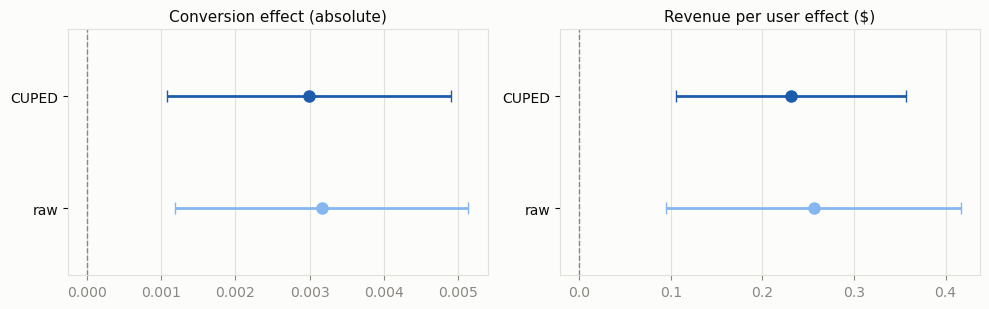

In [3]:
fig = plot_ci_comparison({
    "Conversion effect (absolute)": {"raw": conv_raw, "cuped": conv_cuped},
    "Revenue per user effect ($)": {"raw": rev_raw, "cuped": rev_cuped},
})

## 2. What variance reduction buys: shorter experiments

Required sample size scales linearly with metric variance, so a variance reduction of $\rho^2$ means the same power with $(1 - \rho^2) \times n$ users. At the traffic assumption from config, that converts directly into days.

conversion: same power with 6.3% fewer users = 0.9 fewer days at 10,000 users/day (14.0 -> 13.2 days)
revenue: same power with 39.0% fewer users = 5.5 fewer days at 10,000 users/day (14.0 -> 8.6 days)


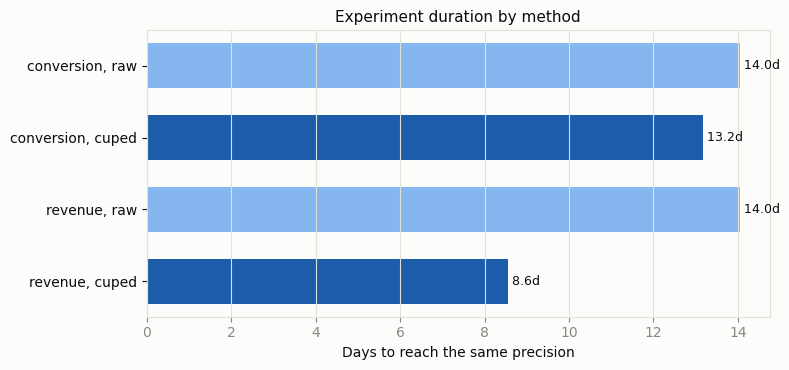

In [4]:
days_raw = 2 * n_per_arm / config.USERS_PER_DAY

days = {}
for label, rho in [("conversion", rho_conv), ("revenue", rho_rev)]:
    days[label] = {"raw": days_raw, "cuped": days_raw * (1 - rho**2)}
    saved = days[label]["raw"] - days[label]["cuped"]
    print(f"{label}: same power with {rho**2:.1%} fewer users = "
          f"{saved:.1f} fewer days at {config.USERS_PER_DAY:,} users/day "
          f"({days[label]['raw']:.1f} -> {days[label]['cuped']:.1f} days)")

fig = plot_duration_comparison(days)

## Takeaways

- CUPED on revenue per user removes ~39% of the metric variance, matching the theoretical $\rho^2$ exactly; the CI narrows by ~22% (narrowing goes as $1 - \sqrt{1-\rho^2}$).
- CUPED on rare binary conversion gives a real but small improvement (~6% variance reduction), as expected from the correlation cap; the experiment on the primary metric shortens by less than a day.
- Unbiasedness and false-positive-rate safety are verified over thousands of simulations in `validate_phase2.py` (G2a-G2c).